<a href="https://colab.research.google.com/github/fattah-abdullah/ProyekAkhir_5A_CardiovascularDisease/blob/main/01_eksplorasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bagian 1 — Persiapan dan pemuatan dataset

### Install Library tambahan (gdown)

In [19]:
!pip -q install gdown

### Import Library

In [20]:
# Import library pengolahan data
import pandas as pd
import numpy as np

# Import library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Import library tambahan
import os
import gdown

### Load Data dari Google Drive

In [21]:
# Masukkan link Google Drive yang berisi cardio_train.csv
drive_url = "https://drive.google.com/file/d/1WCGgJ-fTcaGpCIRoNXPJNPQuqJzJ_nuD/view?usp=drive_link"

# Nama file lokal setelah diunduh
file_path = "cardio_train.csv"

# Mengunduh dataset dari Google Drive
gdown.download(
    url=drive_url,
    output=file_path,
    fuzzy=True,
    quiet=False
)
df = pd.read_csv(file_path, sep=';')

# Menampilkan informasi awal dataset
print("\nDataset berhasil dimuat!")
print("Nama file:", file_path)

display(df.head())

Downloading...
From: https://drive.google.com/uc?id=1WCGgJ-fTcaGpCIRoNXPJNPQuqJzJ_nuD
To: /content/cardio_train.csv
100%|██████████| 2.94M/2.94M [00:00<00:00, 100MB/s]



Dataset berhasil dimuat!
Nama file: cardio_train.csv


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


# Bagian 2 — Exploratory Data Analysis (EDA)

## A. Pemeriksaan awal dataset

### Kamus data

In [22]:
kamus_data = pd.DataFrame({
    'Kolom': [
        'id', 'age', 'gender', 'height', 'weight',
        'ap_hi', 'ap_lo', 'cholesterol', 'gluc',
        'smoke', 'alco', 'active', 'cardio'
    ],

    'Deskripsi': [
        'Identitas unik pemeriksaan',
        'Umur pasien dalam hari',
        'Jenis kelamin berkode 1 dan 2',
        'Tinggi badan',
        'Berat badan',
        'Tekanan darah sistolik',
        'Tekanan darah diastolik',
        'Kategori kolesterol',
        'Kategori glukosa',
        'Status merokok',
        'Konsumsi alkohol',
        'Aktivitas fisik',
        'Status penyakit kardiovaskular'
    ],

    'Satuan/Kategori': [
        '-', 'Hari', '1 atau 2', 'cm', 'kg',
        'mmHg', 'mmHg', '1-3', '1-3',
        '0 atau 1', '0 atau 1', '0 atau 1',
        '0 atau 1'
    ]
})

display(kamus_data)

,Kolom,Deskripsi,Satuan/Kategori
0,id,Identitas unik pemeriksaan,-
1,age,Umur pasien dalam hari,Hari
2,gender,Jenis kelamin berkode 1 dan 2,1 atau 2
3,height,Tinggi badan,cm
4,weight,Berat badan,kg
5,ap_hi,Tekanan darah sistolik,mmHg
6,ap_lo,Tekanan darah diastolik,mmHg
7,cholesterol,Kategori kolesterol,1-3
8,gluc,Kategori glukosa,1-3
9,smoke,Status merokok,0 atau 1


### Informasi dataset

In [23]:
# Menampilkan dimensi dataset
print("Dimensi Dataset:", df.shape)
print("Jumlah Baris:", df.shape[0])
print("Jumlah Kolom:", df.shape[1])

# Menampilkan lima data pertama
print("\nLima Data Pertama:")
display(df.head())

# Menampilkan lima data terakhir
print("\nLima Data Terakhir:")
display(df.tail())

# Memeriksa tipe data dan kelengkapan setiap kolom
print("\nInformasi Dataset:")
df.info()

Dimensi Dataset: (70000, 13)
Jumlah Baris: 70000
Jumlah Kolom: 13

Lima Data Pertama:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0



Lima Data Terakhir:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1
69999,99999,20540,1,170,72.0,120,80,2,1,0,0,1,0



Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


### Pemeriksaan Jumlah Nilai Unik

In [24]:
data_info = pd.DataFrame({
    "Nama Kolom": df.columns,
    "Jumlah Nilai Unik": df.nunique().values
})

display(data_info)

,Nama Kolom,Jumlah Nilai Unik
0,id,70000
1,age,8076
2,gender,2
3,height,109
4,weight,287
5,ap_hi,153
6,ap_lo,157
7,cholesterol,3
8,gluc,3
9,smoke,2


### Memeriksa nilai tidak valid pada kolom numerik

In [25]:
# Memeriksa nilai nol dan negatif pada kolom numerik
kolom_pemeriksaan = [
    'ap_hi', 'ap_lo', 'height', 'weight'
]

for kolom in kolom_pemeriksaan:

    print(f"\nKolom: {kolom}")
    print("Nilai nol:", (df[kolom] == 0).sum())
    print("Nilai negatif:", (df[kolom] < 0).sum())


Kolom: ap_hi
Nilai nol: 0
Nilai negatif: 7

Kolom: ap_lo
Nilai nol: 21
Nilai negatif: 1

Kolom: height
Nilai nol: 0
Nilai negatif: 0

Kolom: weight
Nilai nol: 0
Nilai negatif: 0


### Pemeriksaan missing values

In [26]:
missing_data = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase Missing (%)": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_data)

,Jumlah Missing,Persentase Missing (%)
id,0,0.0
age,0,0.0
gender,0,0.0
height,0,0.0
weight,0,0.0
ap_hi,0,0.0
ap_lo,0,0.0
cholesterol,0,0.0
gluc,0,0.0
smoke,0,0.0


### Pemeriksaan konsistensi tekanan darah

In [27]:
invalid_blood_pressure = (
    df["ap_hi"] < df["ap_lo"]
)

print(
    "Jumlah ap_hi lebih kecil dari ap_lo:",
    invalid_blood_pressure.sum()
)

Jumlah ap_hi lebih kecil dari ap_lo: 1234


### Pemeriksaan Data Duplikat

In [28]:
# Menghitung duplikat seluruh baris
jumlah_duplikat = df.duplicated().sum()

# Memeriksa identifier yang berulang
jumlah_id_duplikat = df['id'].duplicated().sum()

print("Jumlah duplikat seluruh baris:", jumlah_duplikat)
print("Jumlah ID yang berulang:", jumlah_id_duplikat)

Jumlah duplikat seluruh baris: 0
Jumlah ID yang berulang: 0


## B. Univariate Analysis

### Statistik deskriptif

In [29]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


### Distribusi fitur numerik

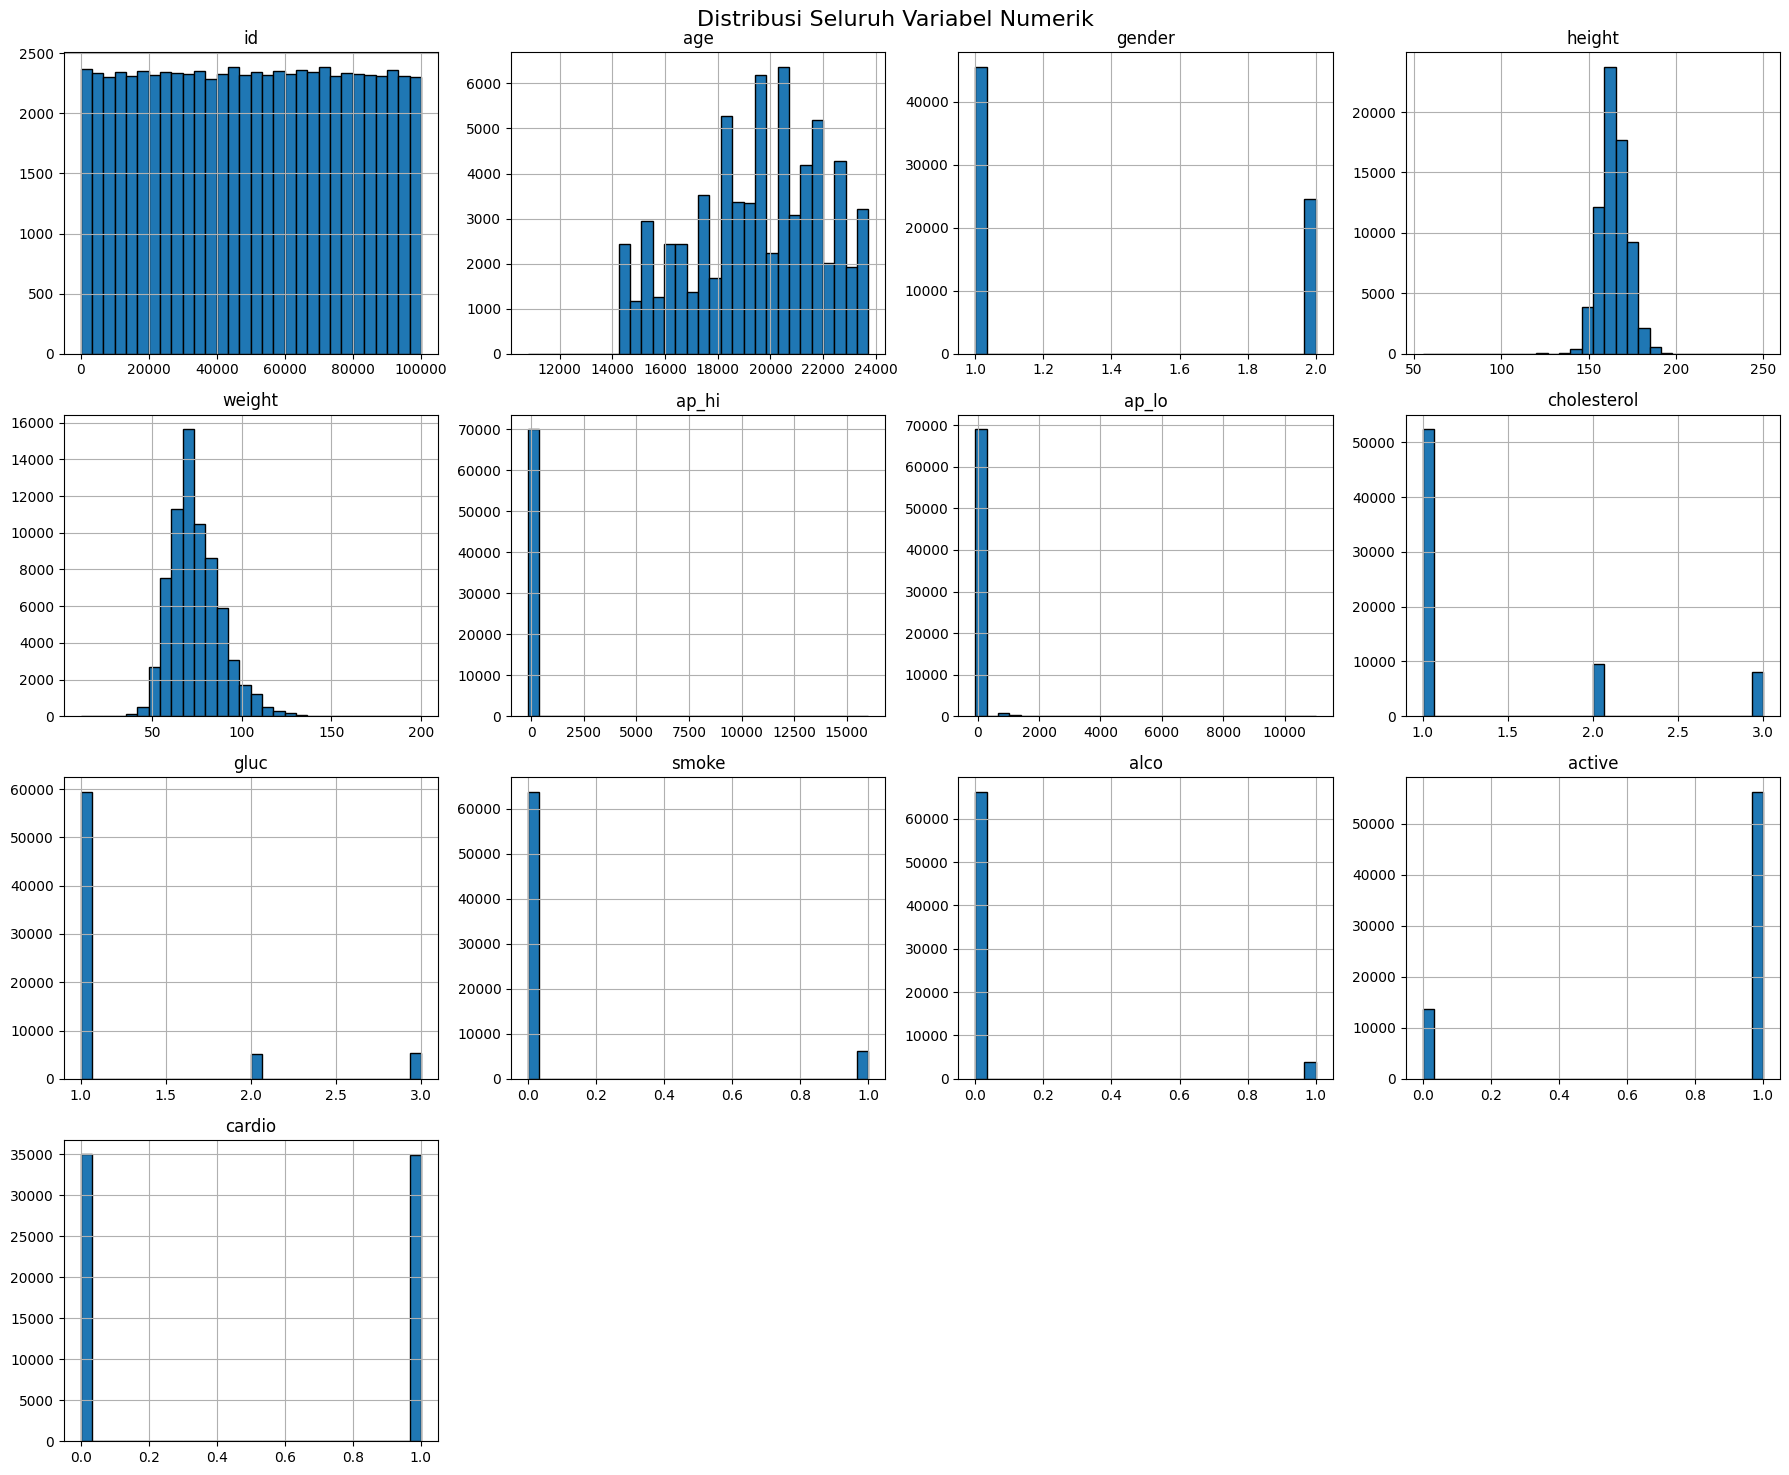

In [30]:
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

df[numeric_columns].hist(
    bins=30,
    figsize=(18, 15),
    edgecolor="black"
)

plt.suptitle(
    "Distribusi Seluruh Variabel Numerik",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Boxplot seluruh fitur numerik

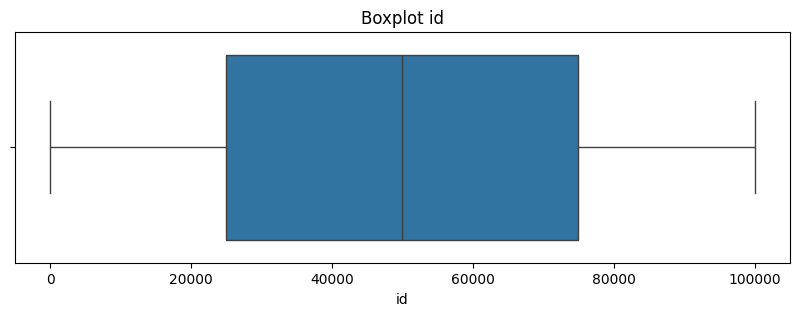

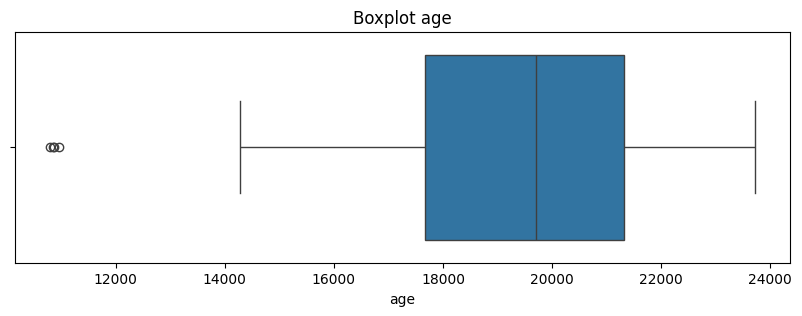

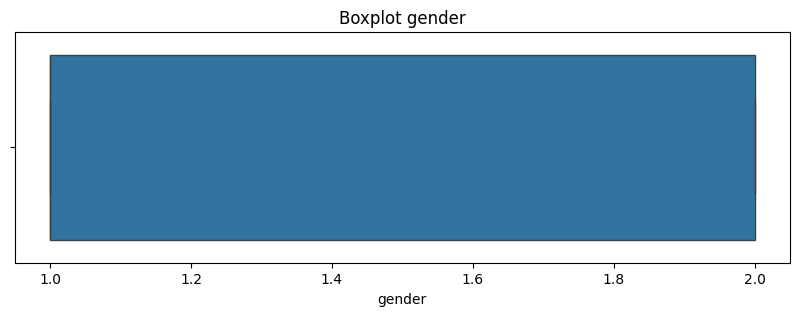

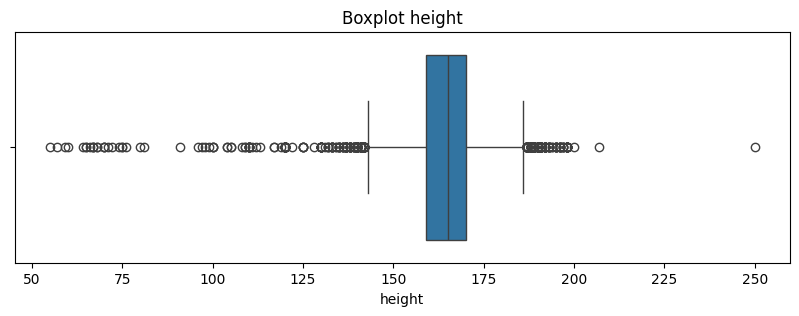

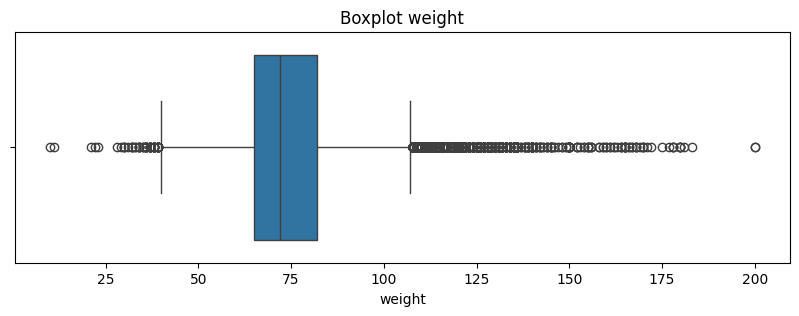

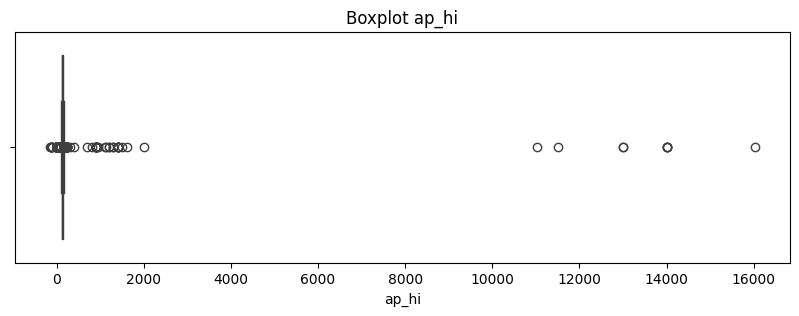

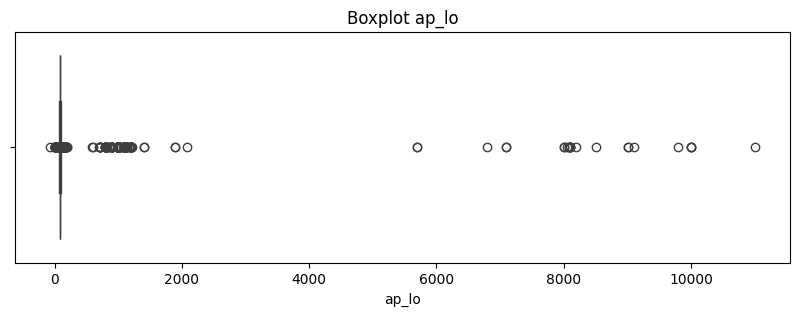

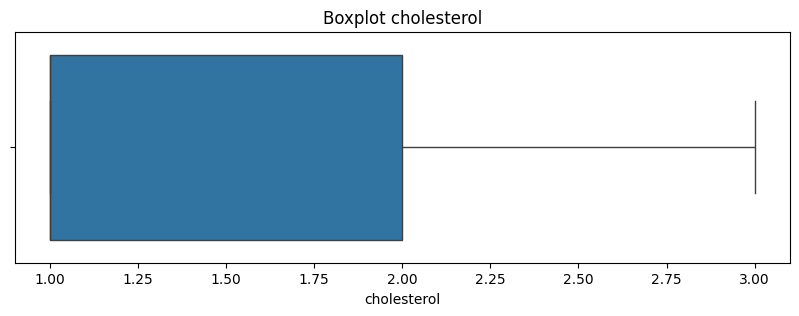

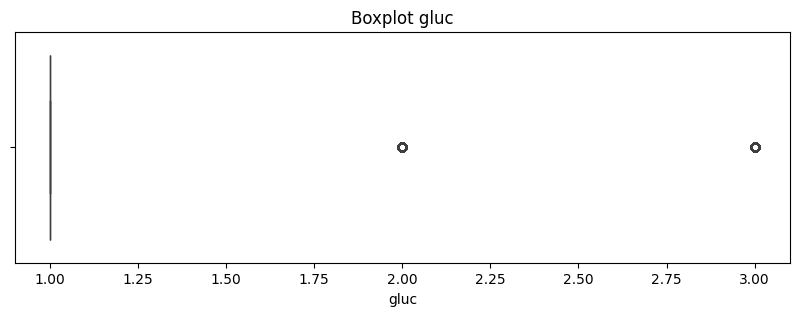

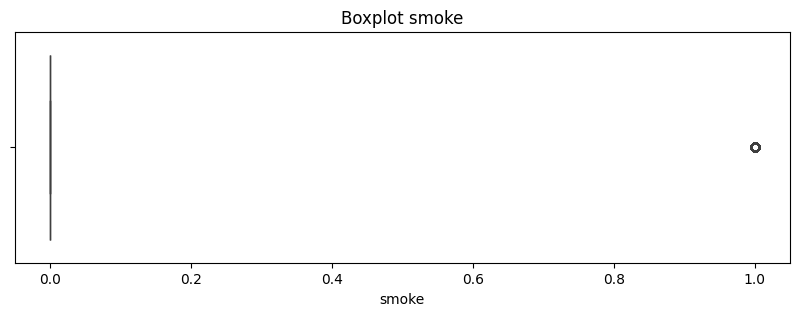

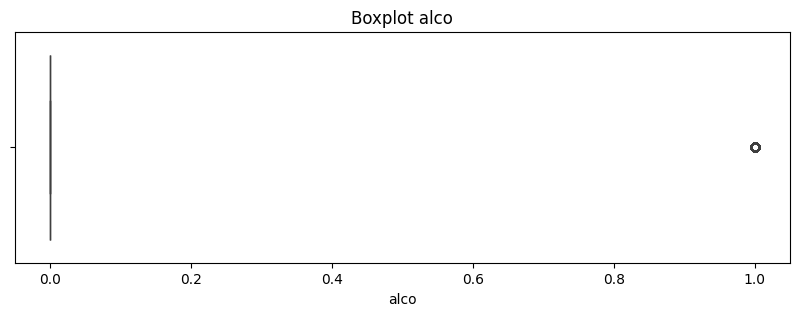

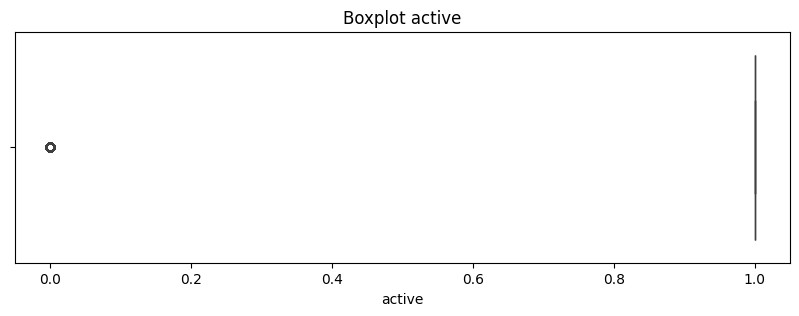

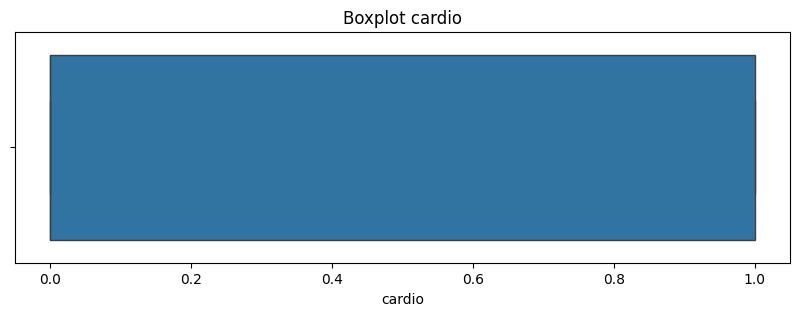

In [31]:
for column in numeric_columns:
    plt.figure(figsize=(10, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot {column}")
    plt.xlabel(column)

    plt.show()

### Distribusi fitur kategorikal

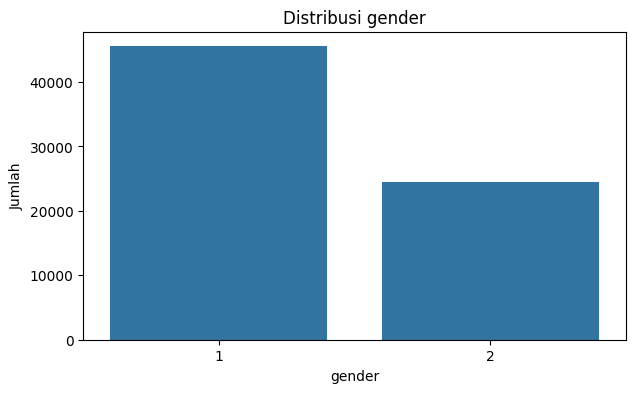

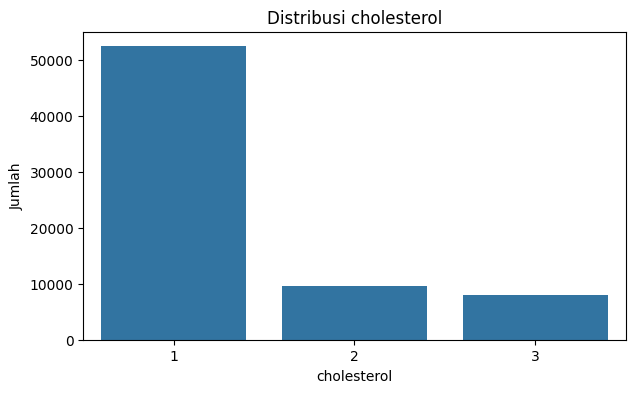

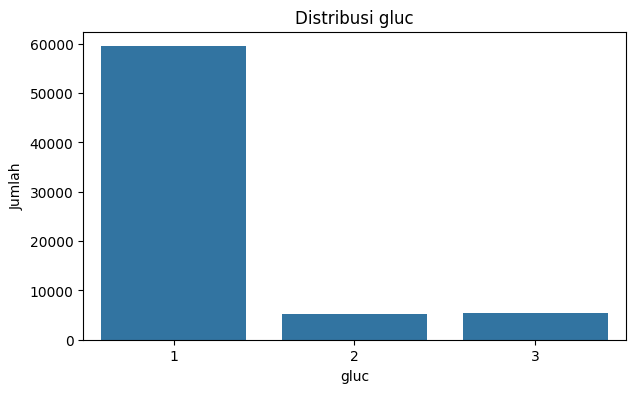

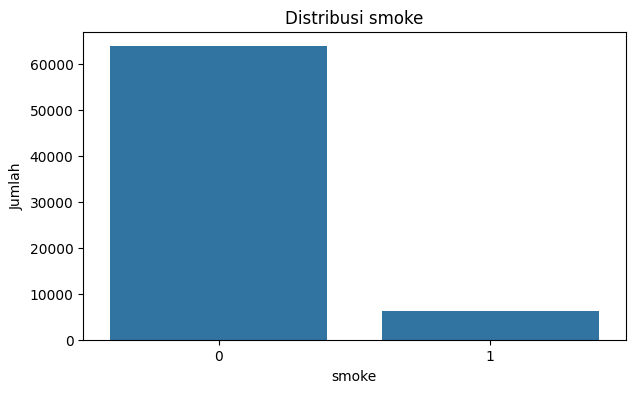

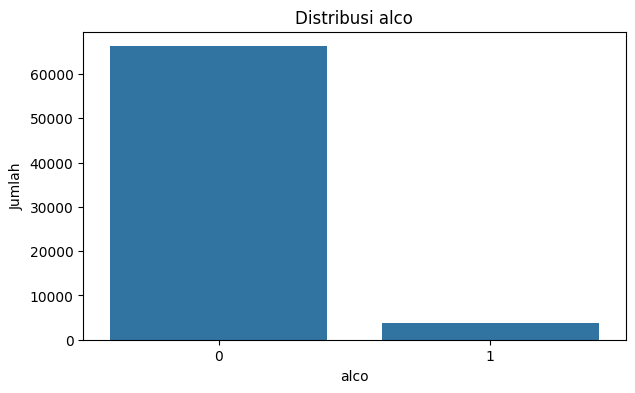

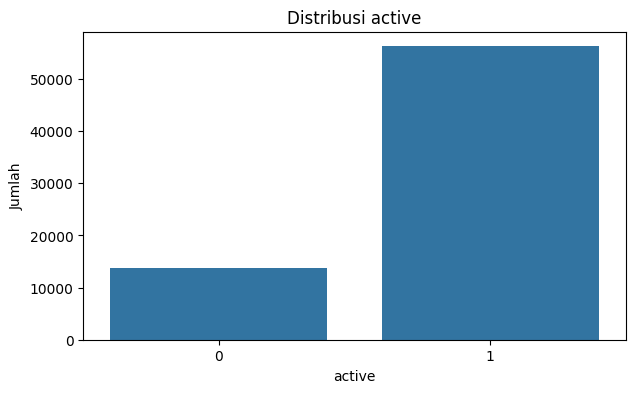

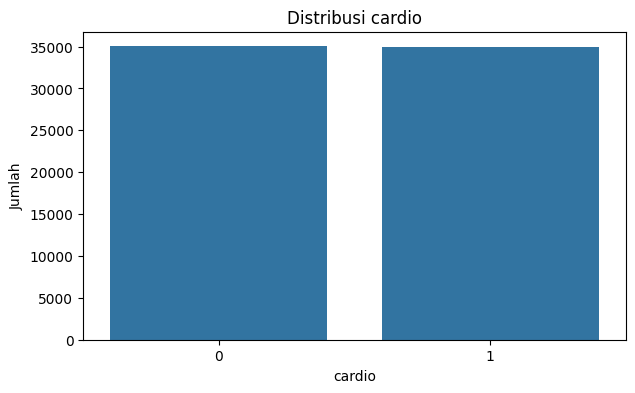

In [32]:
categorical_columns = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "cardio"
]

for column in categorical_columns:
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=column
    )

    plt.title(f"Distribusi {column}")
    plt.xlabel(column)
    plt.ylabel("Jumlah")

    plt.show()

## C. Bivariate Analysis

### Korelasi fitur dengan target

In [33]:
target = "ap_hi"

correlation_target = (
    df.corr(numeric_only=True)[target]
    .sort_values(ascending=False)
)

display(
    correlation_target.to_frame(
        name="Korelasi dengan ap_hi"
    )
)

,Korelasi dengan ap_hi
ap_hi,1.000000
cardio,0.054475
weight,0.030702
cholesterol,0.023778
age,0.020764
ap_lo,0.016086
gluc,0.011841
gender,0.006005
height,0.005488
id,0.003356


### Scatterplot fitur numerik terhadap target

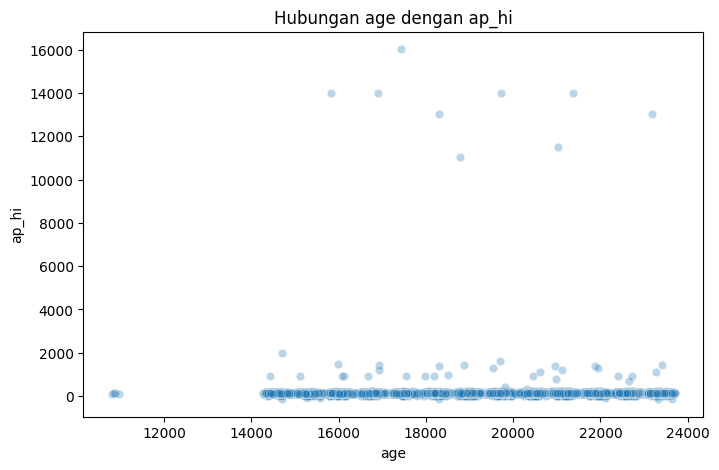

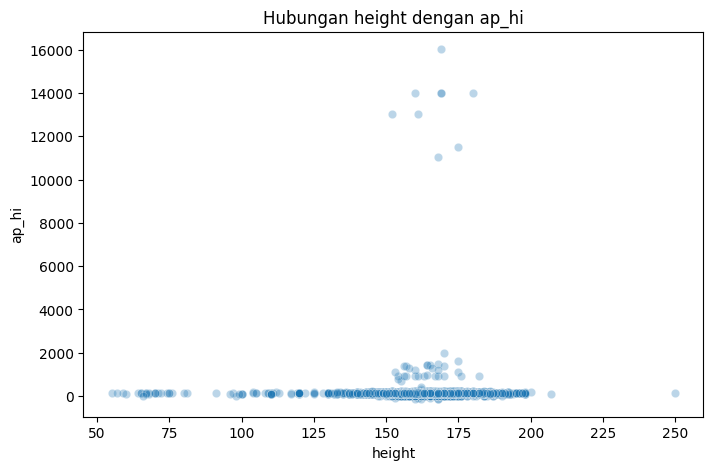

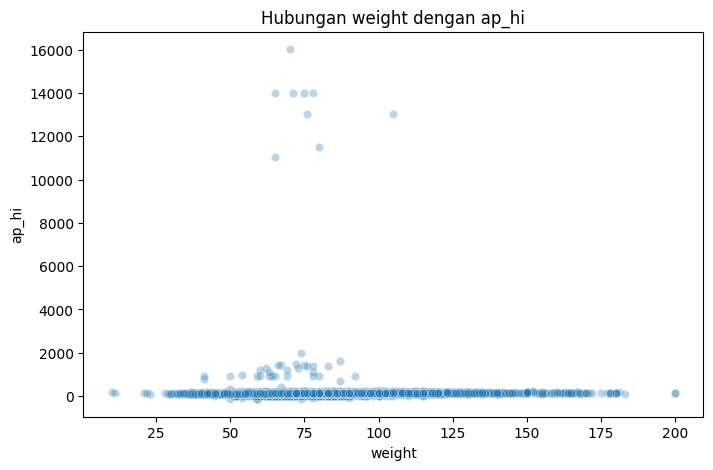

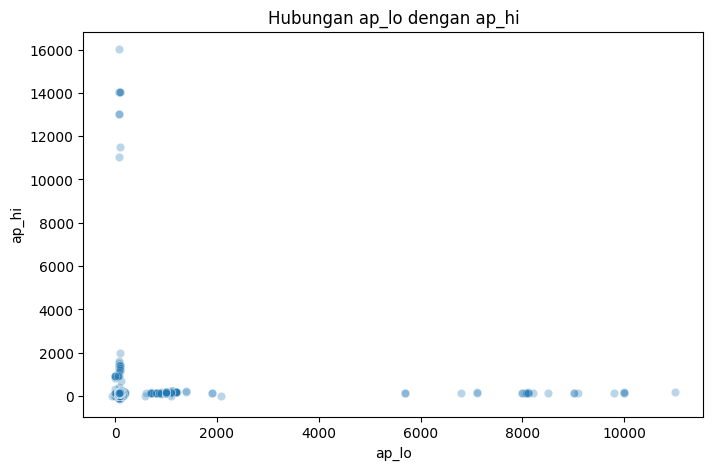

In [34]:
scatter_features = [
    "age",
    "height",
    "weight",
    "ap_lo"
]

for column in scatter_features:
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=column,
        y="ap_hi",
        alpha=0.3
    )

    plt.title(f"Hubungan {column} dengan ap_hi")
    plt.xlabel(column)
    plt.ylabel("ap_hi")

    plt.show()

### Hubungan fitur kategorikal dengan target

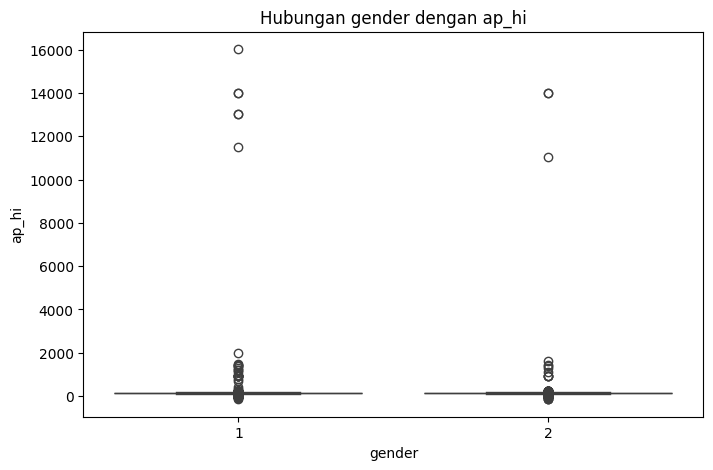

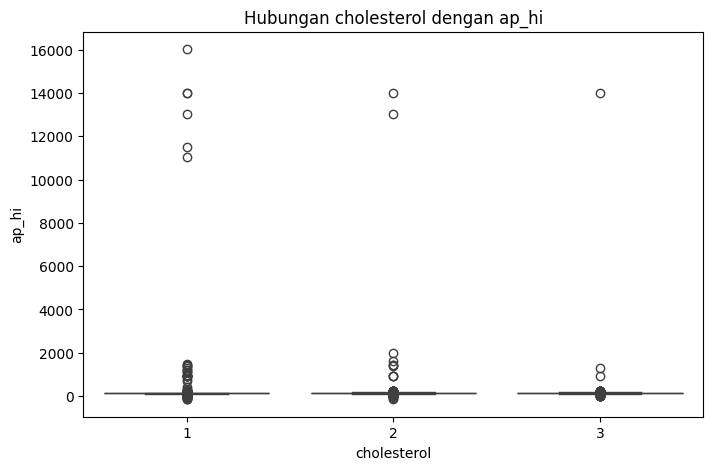

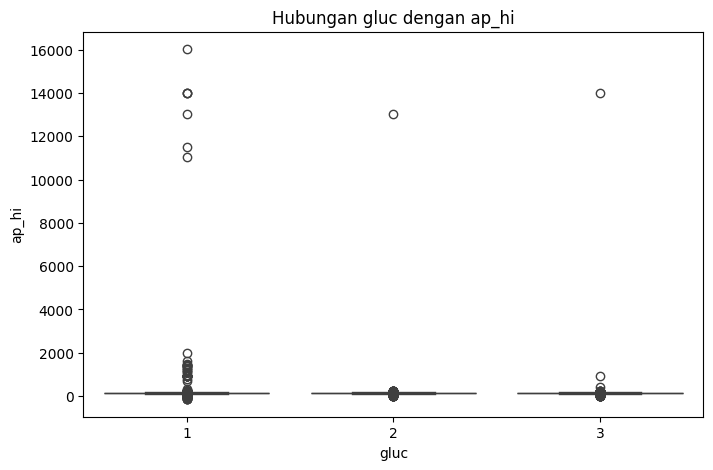

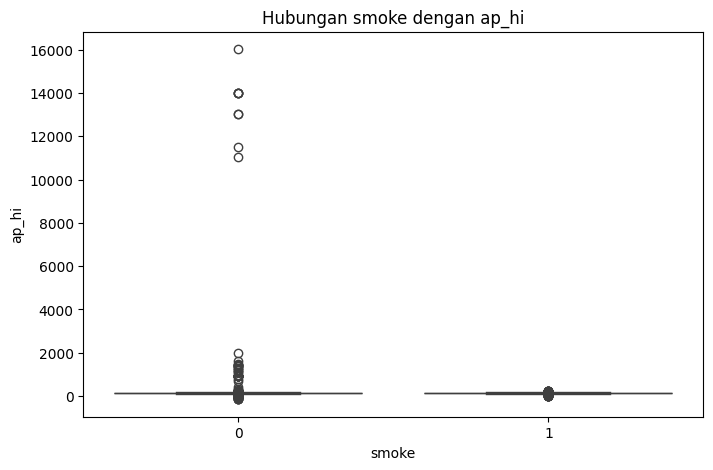

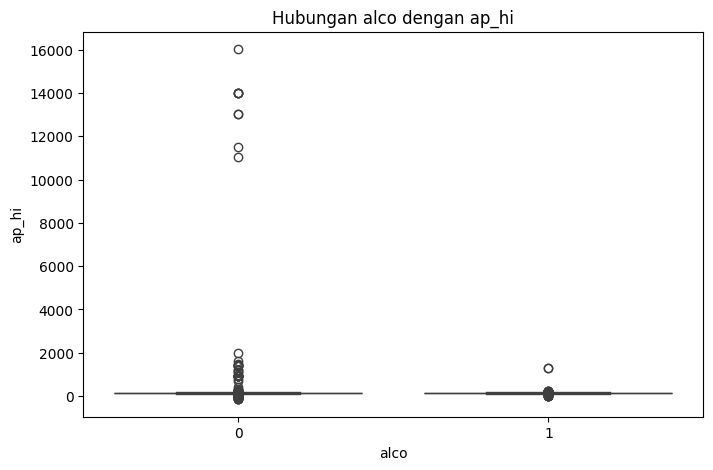

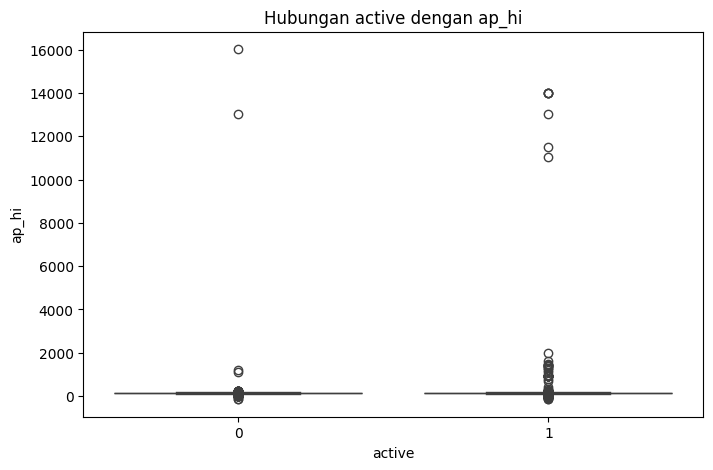

In [35]:
for column in categorical_columns:
    if column == "cardio":
        continue

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=column,
        y="ap_hi"
    )

    plt.title(f"Hubungan {column} dengan ap_hi")
    plt.xlabel(column)
    plt.ylabel("ap_hi")

    plt.show()

## D. Multivariate Analysis

### Correlation heatmap

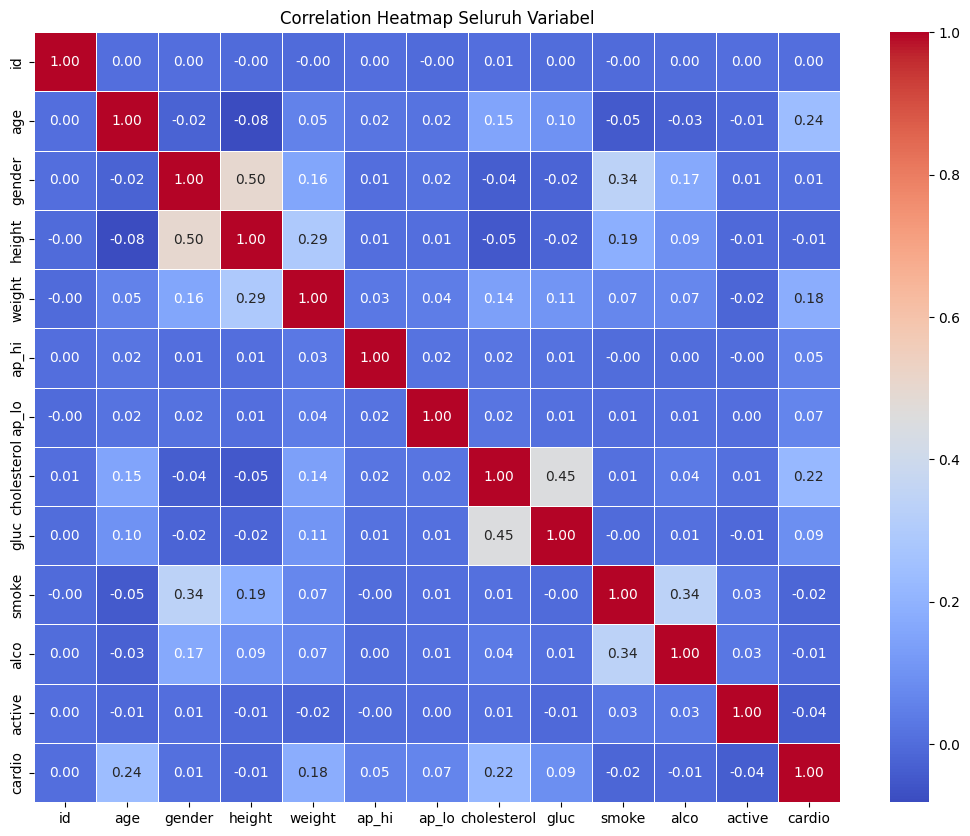

In [36]:
correlation_matrix = df.corr(
    numeric_only=True
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap Seluruh Variabel")
plt.show()

### Pairplot

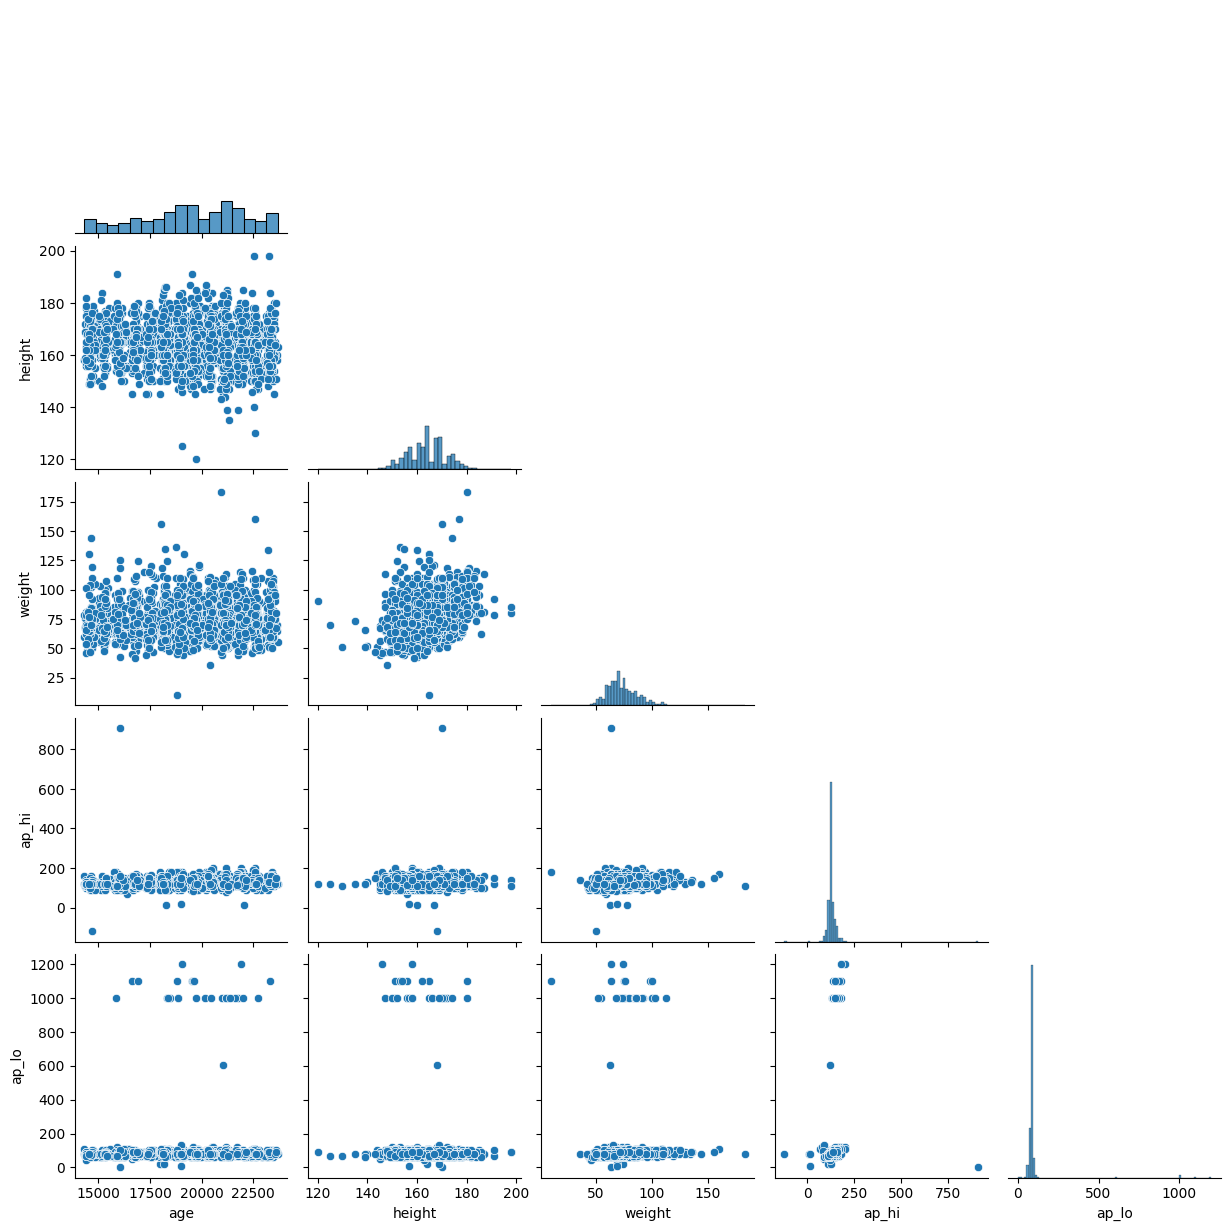

In [37]:
pairplot_columns = [
    "age",
    "height",
    "weight",
    "ap_hi",
    "ap_lo"
]

sns.pairplot(
    df[pairplot_columns].sample(
        n=min(2000, len(df)),
        random_state=42
    ),
    diag_kind="hist",
    corner=True
)

plt.show()

### Hubungan beberapa fitur berdasarkan target kategori cardio

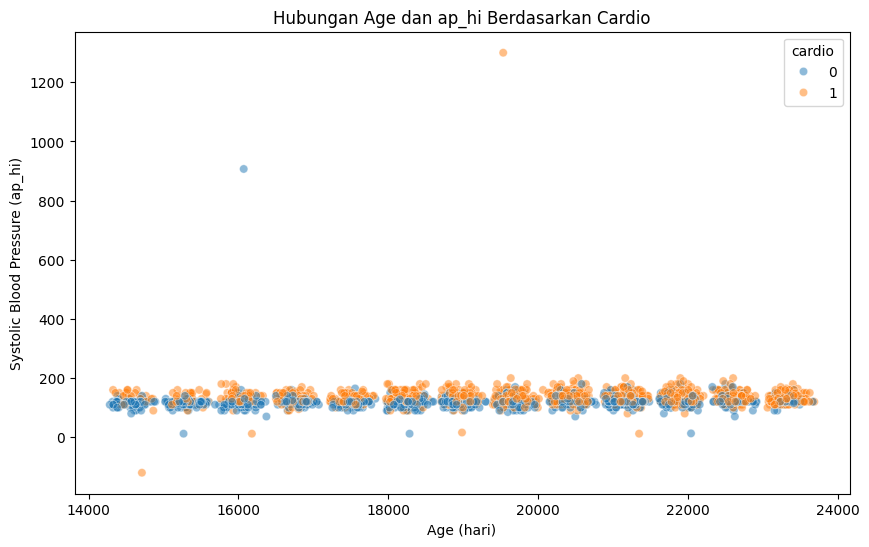

In [38]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df.sample(
        n=min(3000, len(df)),
        random_state=42
    ),
    x="age",
    y="ap_hi",
    hue="cardio",
    alpha=0.5
)

plt.title("Hubungan Age dan ap_hi Berdasarkan Cardio")
plt.xlabel("Age (hari)")
plt.ylabel("Systolic Blood Pressure (ap_hi)")

plt.show()

### Ringkasan korelasi

In [39]:
correlation_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Variabel 1",
    "Variabel 2",
    "Korelasi"
]

correlation_pairs["Korelasi Absolut"] = (
    correlation_pairs["Korelasi"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    by="Korelasi Absolut",
    ascending=False
)

display(correlation_pairs.head(15))

,Variabel 1,Variabel 2,Korelasi,Korelasi Absolut
23,gender,height,0.499033,0.499033
63,cholesterol,gluc,0.451578,0.451578
72,smoke,alco,0.340094,0.340094
29,gender,smoke,0.338135,0.338135
33,height,weight,0.290968,0.290968
22,age,cardio,0.238159,0.238159
67,cholesterol,cardio,0.221147,0.221147
38,height,smoke,0.187989,0.187989
49,weight,cardio,0.181660,0.181660
30,gender,alco,0.170966,0.170966


### Ringkasan hasil EDA

In [40]:
print("========== RINGKASAN EDA ==========")

print("\n1. Informasi Dataset")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\n2. Missing Values")
print("Total missing values:", df.isnull().sum().sum())

print("\n3. Duplikasi")
print("Jumlah baris duplikat:", df.duplicated().sum())

print("\n4. Statistik Target ap_hi")
print(df["ap_hi"].describe())

print("\n5. Korelasi terhadap Target ap_hi")
display(correlation_target)

========== RINGKASAN EDA ==========

1. Informasi Dataset
Jumlah baris: 70000
Jumlah kolom: 13

2. Missing Values
Total missing values: 0

3. Duplikasi
Jumlah baris duplikat: 0

4. Statistik Target ap_hi
count    70000.000000
mean       128.817286
std        154.011419
min       -150.000000
25%        120.000000
50%        120.000000
75%        140.000000
max      16020.000000
Name: ap_hi, dtype: float64

5. Korelasi terhadap Target ap_hi


,ap_hi
ap_hi,1.000000
cardio,0.054475
weight,0.030702
cholesterol,0.023778
age,0.020764
ap_lo,0.016086
gluc,0.011841
gender,0.006005
height,0.005488
id,0.003356
